# Notebook 05: Phân tích Sai số (Error Analysis)

Nguồn: `oof_predictions.csv` (E0) join với `X` theo `row_index`.

> **Lưu ý:** Mọi số liệu lấy từ file CSV. Không huấn luyện lại mô hình chính trong notebook này.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.tree import export_text

from config import TABLES_DIR, FIGURES_DIR, SEED, MODEL_NAMES
from evaluation import (
    df_to_markdown, misclassified_table, error_rate_by_group,
    consistent_errors, permutation_importance_cv, lr_coefficients_table,
    plot_error_rate_by_group, plot_permutation_importance, plot_lr_coefficients
)
from pipelines import get_models
from train import load_xy, make_folds

# Đọc dữ liệu
X, y = load_xy()
folds = make_folds(X, y)
oof_df = pd.read_csv(TABLES_DIR / 'oof_predictions.csv', encoding='utf-8')
print('Dữ liệu đọc xong. X.shape =', X.shape)

[load_xy] X.shape = (101, 6), y.value_counts() =
Do you have Depression?
0    66
1    35
[make_folds] Đã lưu D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\tables\fold_assignments.csv
  Fold 0: test_size=21, n_yes=7
  Fold 1: test_size=20, n_yes=7
  Fold 2: test_size=20, n_yes=7
  Fold 3: test_size=20, n_yes=7
  Fold 4: test_size=20, n_yes=7
Dữ liệu đọc xong. X.shape = (101, 6)


## 1. Ma trận nhầm lẫn (gộp out-of-fold)

Đã lưu: D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\figures\01_confusion_matrices_e0.png


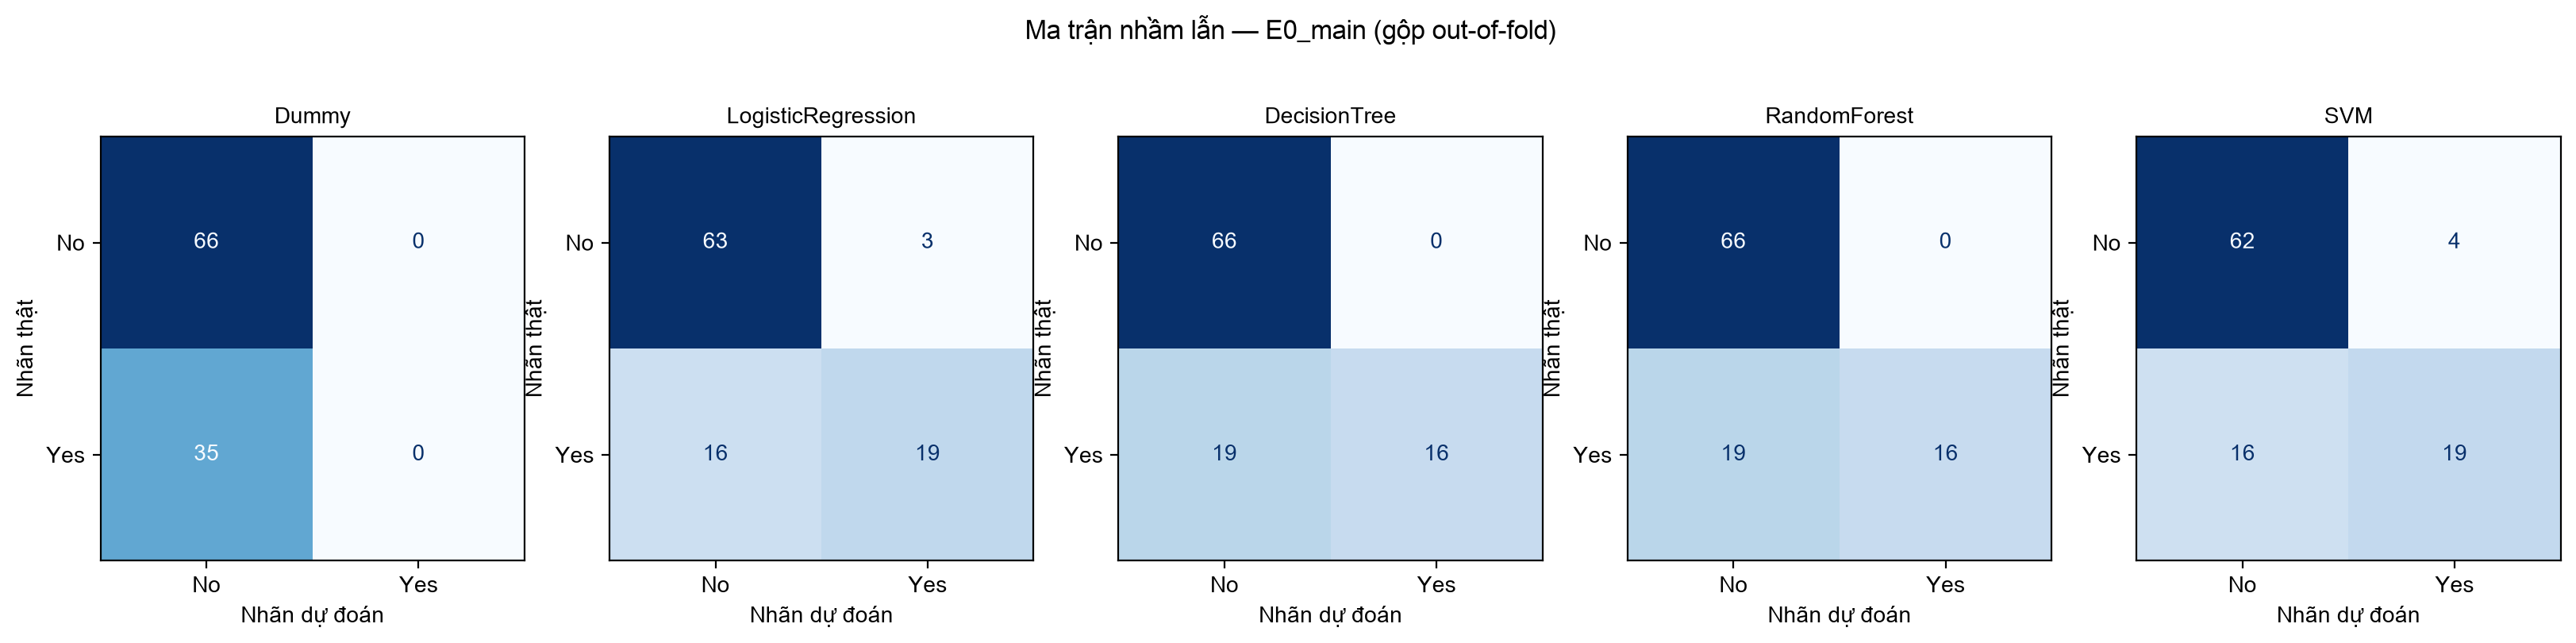

In [2]:
from evaluation import plot_confusion_matrices
from IPython.display import Image
fig_path = plot_confusion_matrices(oof_df, experiment='E0_main', models=MODEL_NAMES)
print(f'Đã lưu: {fig_path}')
Image(str(fig_path))

## 2. Bảng FN và FP

In [3]:
# Chọn mô hình có f1_yes_mean cao nhất ở E0
metrics_df = pd.read_csv(TABLES_DIR / 'metrics_per_fold.csv', encoding='utf-8')
e0 = metrics_df[metrics_df['experiment'] == 'E0_main']
best_model = e0.groupby('model')['f1_yes'].mean().idxmax()
print(f'Mô hình có F1(Yes) trung bình cao nhất: {best_model}')

models_to_analyze = list(dict.fromkeys(['LogisticRegression', best_model]))
if best_model == 'LogisticRegression':
    models_to_analyze = ['LogisticRegression', 'RandomForest']

for model in models_to_analyze:
    for etype in ['fn', 'fp']:
        tbl = misclassified_table(oof_df, X.reset_index(drop=True), model, 
                                  experiment='E0_main', error_type=etype)
        fname = f'error_{etype}_{model}.csv'
        tbl.to_csv(TABLES_DIR / fname, index=False, encoding='utf-8')
        print(f'{model} {etype.upper()} ({len(tbl)} dòng):')
        if not tbl.empty:
            print(df_to_markdown(tbl[['row_index','fold','y_true','y_pred'] + list(X.columns)]))
        print()

Mô hình có F1(Yes) trung bình cao nhất: LogisticRegression
LogisticRegression FN (16 dòng):
|   row_index |   fold |   y_true |   y_pred | Choose your gender   |    Age | What is your course?   | Your current year of Study   | What is your CGPA?   | Marital status   |
|------------:|-------:|---------:|---------:|:---------------------|-------:|:-----------------------|:-----------------------------|:---------------------|:-----------------|
|          36 |      0 |        1 |        0 | Female               | 18.000 | Law                    | year 3                       | 3.00 - 3.49          | No               |
|          42 |      0 |        1 |        0 | Female               | 20.000 | Usuluddin              | year 2                       | 3.00 - 3.49          | No               |
|          57 |      0 |        1 |        0 | Female               | 20.000 | BENL                   | year 3                       | 3.00 - 3.49          | No               |
|          85 |      0 

## 3. Tỷ lệ sai theo nhóm

In [4]:
# Phân tích theo nhiều feature cho LR (mô hình chính)
feature_groups = [
    ('Marital status', None),
    ('What is your CGPA?', None),
    ('Your current year of Study', None),
    ('Choose your gender', None),
    ('Age', [17, 20, 23, 25]),  # nhóm tuổi: 18-19, 20-22, 23-24
]

all_error_rates = []
for feat, age_bins in feature_groups:
    tbl = error_rate_by_group(oof_df, X.reset_index(drop=True), feat, 'LogisticRegression',
                               experiment='E0_main', age_bins=age_bins)
    print(f'Tỷ lệ sai theo {feat}:')
    print(df_to_markdown(tbl))
    print('  (Nhóm n < 10 rất bất ổn)')
    print()
    all_error_rates.append(tbl)

error_rates_df = pd.concat(all_error_rates, ignore_index=True)
error_rates_df.to_csv(TABLES_DIR / 'error_by_group.csv', index=False, encoding='utf-8')

Tỷ lệ sai theo Marital status:
| feature        | group_value   |   n |   n_errors |   error_rate |
|:---------------|:--------------|----:|-----------:|-------------:|
| Marital status | No            |  85 |         19 |        0.224 |
| Marital status | Yes           |  16 |          0 |        0.000 |
  (Nhóm n < 10 rất bất ổn)

Tỷ lệ sai theo What is your CGPA?:
| feature            | group_value   |   n |   n_errors |   error_rate |
|:-------------------|:--------------|----:|-----------:|-------------:|
| What is your CGPA? | 0 - 1.99      |   4 |          0 |        0.000 |
| What is your CGPA? | 2.00 - 2.49   |   2 |          1 |        0.500 |
| What is your CGPA? | 2.50 - 2.99   |   4 |          0 |        0.000 |
| What is your CGPA? | 3.00 - 3.49   |  43 |         12 |        0.279 |
| What is your CGPA? | 3.50 - 4.00   |  48 |          6 |        0.125 |
  (Nhóm n < 10 rất bất ổn)

Tỷ lệ sai theo Your current year of Study:
| feature                    | group_value   |  

Đã lưu: D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\figures\07_error_rate_by_group.png


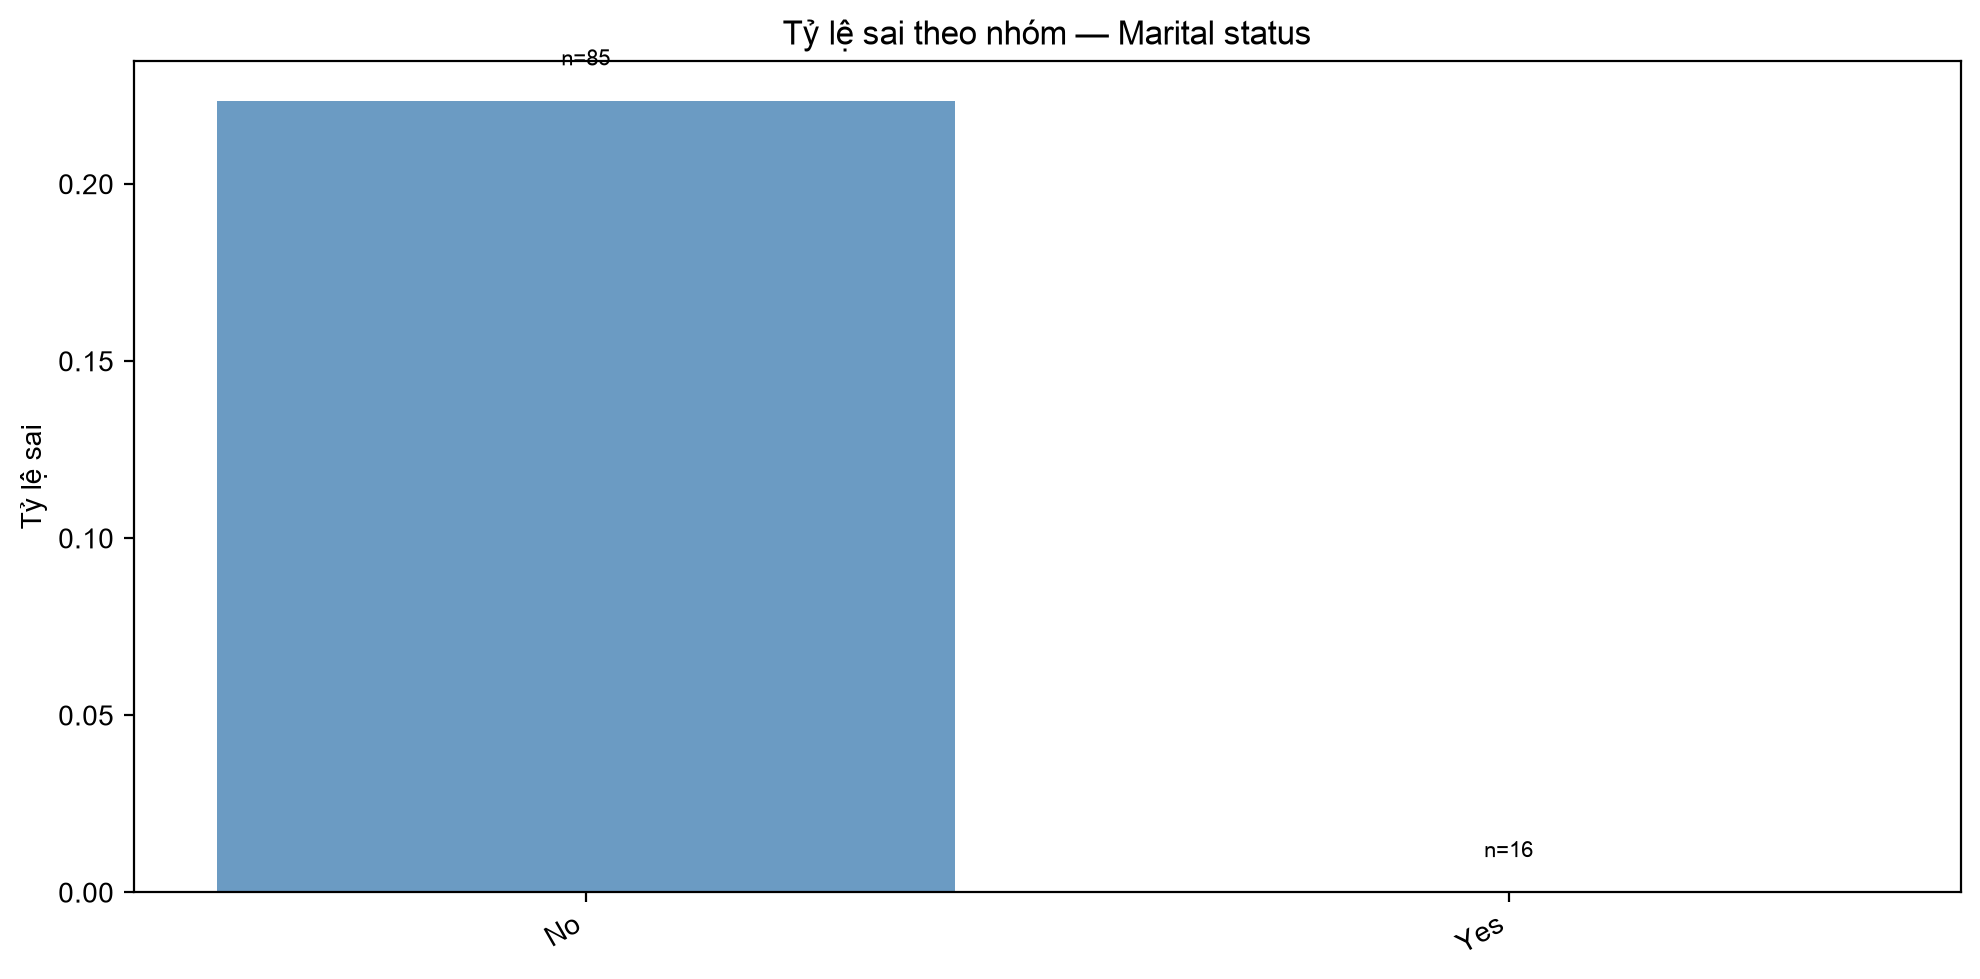

In [5]:
# Vẽ hình 07 (theo Marital status để minh họa)
marital_tbl = all_error_rates[0]
fig_path = plot_error_rate_by_group(marital_tbl)
print(f'Đã lưu: {fig_path}')
Image(str(fig_path))

## 4. Dòng bị mọi mô hình sai

In [6]:
consistent = consistent_errors(oof_df, experiment='E0_main')
consistent.to_csv(TABLES_DIR / 'error_consistent.csv', index=False, encoding='utf-8')
print(f'Số dòng bị mọi mô hình (trừ Dummy) sai: {len(consistent)}')
if not consistent.empty:
    print(df_to_markdown(consistent))
    # Đối chiếu với dữ liệu
    for _, row in consistent.iterrows():
        ri = int(row['row_index'])
        print(f'  Row {ri}: y_true={row["y_true"]}, features=')
        print(f'    {X.iloc[ri].to_dict()}')

Số dòng bị mọi mô hình (trừ Dummy) sai: 16
|   row_index |   n_models_wrong |   y_true |
|------------:|-----------------:|---------:|
|           0 |                4 |        1 |
|           2 |                4 |        1 |
|          12 |                4 |        1 |
|          24 |                4 |        1 |
|          36 |                4 |        1 |
|          42 |                4 |        1 |
|          48 |                4 |        1 |
|          54 |                4 |        1 |
|          57 |                4 |        1 |
|          65 |                4 |        1 |
|          68 |                4 |        1 |
|          76 |                4 |        1 |
|          82 |                4 |        1 |
|          85 |                4 |        1 |
|          87 |                4 |        1 |
|          97 |                4 |        1 |
  Row 0: y_true=1, features=
    {'Choose your gender': 'Female', 'Age': 18.0, 'What is your course?': 'Engineering', 'Your curre

## 5. Phân tích Marital status (bắt buộc, D6)

In [7]:
# Bảng chéo Marital status × nhãn
X_full = X.reset_index(drop=True).copy()
X_full['y'] = y.reset_index(drop=True).values
marital_cross = pd.crosstab(X_full['Marital status'], X_full['y'], margins=True)
marital_cross.columns = ['y=No', 'y=Yes', 'Tổng']
print('Bảng chéo Marital status × Nhãn trầm cảm:')
print(df_to_markdown(marital_cross.reset_index()))

print()
print('Nhận xét: Toàn bộ 16 người có Marital status = Yes đều có nhãn Yes.')
print('Điều này có liên hệ rất mạnh với nhãn TRONG MẪU (n=101).')
print('Chưa đủ căn cứ để suy rộng hoặc kết luận nhân quả.')

# Quy tắc đơn giản: đoán Yes nếu Marital = Yes
y_rule = (X_full['Marital status'] == 'Yes').astype(int)
y_true_arr = X_full['y'].values
from sklearn.metrics import precision_score, recall_score
rule_prec = precision_score(y_true_arr, y_rule, zero_division=0)
rule_rec = recall_score(y_true_arr, y_rule, zero_division=0)
print(f'\nQuy tắc "đoán Yes nếu Marital=Yes" (toàn mẫu, chỉ tham chiếu):')
print(f'  Precision: {rule_prec:.3f}, Recall: {rule_rec:.3f}')
print('(Chỉ tham chiếu — không phải mô hình ML)')

Bảng chéo Marital status × Nhãn trầm cảm:
| Marital status   |   y=No |   y=Yes |   Tổng |
|:-----------------|-------:|--------:|-------:|
| No               |     66 |      19 |     85 |
| Yes              |      0 |      16 |     16 |
| All              |     66 |      35 |    101 |

Nhận xét: Toàn bộ 16 người có Marital status = Yes đều có nhãn Yes.
Điều này có liên hệ rất mạnh với nhãn TRONG MẪU (n=101).
Chưa đủ căn cứ để suy rộng hoặc kết luận nhân quả.

Quy tắc "đoán Yes nếu Marital=Yes" (toàn mẫu, chỉ tham chiếu):
  Precision: 1.000, Recall: 0.457
(Chỉ tham chiếu — không phải mô hình ML)


## 6. Tầm quan trọng feature

In [8]:
# Permutation importance (cột gốc — Course là 1 cột)
print('Tính permutation importance (có thể mất vài phút)...')
models = get_models()
perm_df = permutation_importance_cv(
    pipelines=models,
    folds=folds,
    X=X.reset_index(drop=True),
    y=y.reset_index(drop=True),
    models_to_eval=['LogisticRegression', 'RandomForest'],
    n_repeats=30,
)
perm_df.to_csv(TABLES_DIR / 'error_permutation_importance.csv', index=False, encoding='utf-8')
print('Permutation Importance (mean ± std, ROC-AUC):')
print(df_to_markdown(perm_df))
print('\nLưu ý: Không diễn giải nhân quả. Course có nhiều hạng mục hiếm nên dùng permutation thay vì impurity.')

Tính permutation importance (có thể mất vài phút)...


Permutation Importance (mean ± std, ROC-AUC):
| model              | feature                    |   mean_importance |   std_importance |
|:-------------------|:---------------------------|------------------:|-----------------:|
| LogisticRegression | Choose your gender         |             0.008 |            0.058 |
| LogisticRegression | Age                        |             0.007 |            0.048 |
| LogisticRegression | What is your course?       |            -0.006 |            0.079 |
| LogisticRegression | Your current year of Study |             0.013 |            0.040 |
| LogisticRegression | What is your CGPA?         |             0.041 |            0.093 |
| LogisticRegression | Marital status             |             0.276 |            0.133 |
| RandomForest       | Choose your gender         |             0.002 |            0.068 |
| RandomForest       | Age                        |             0.005 |            0.051 |
| RandomForest       | What is your course? 

Đã lưu: D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\figures\08_permutation_importance.png


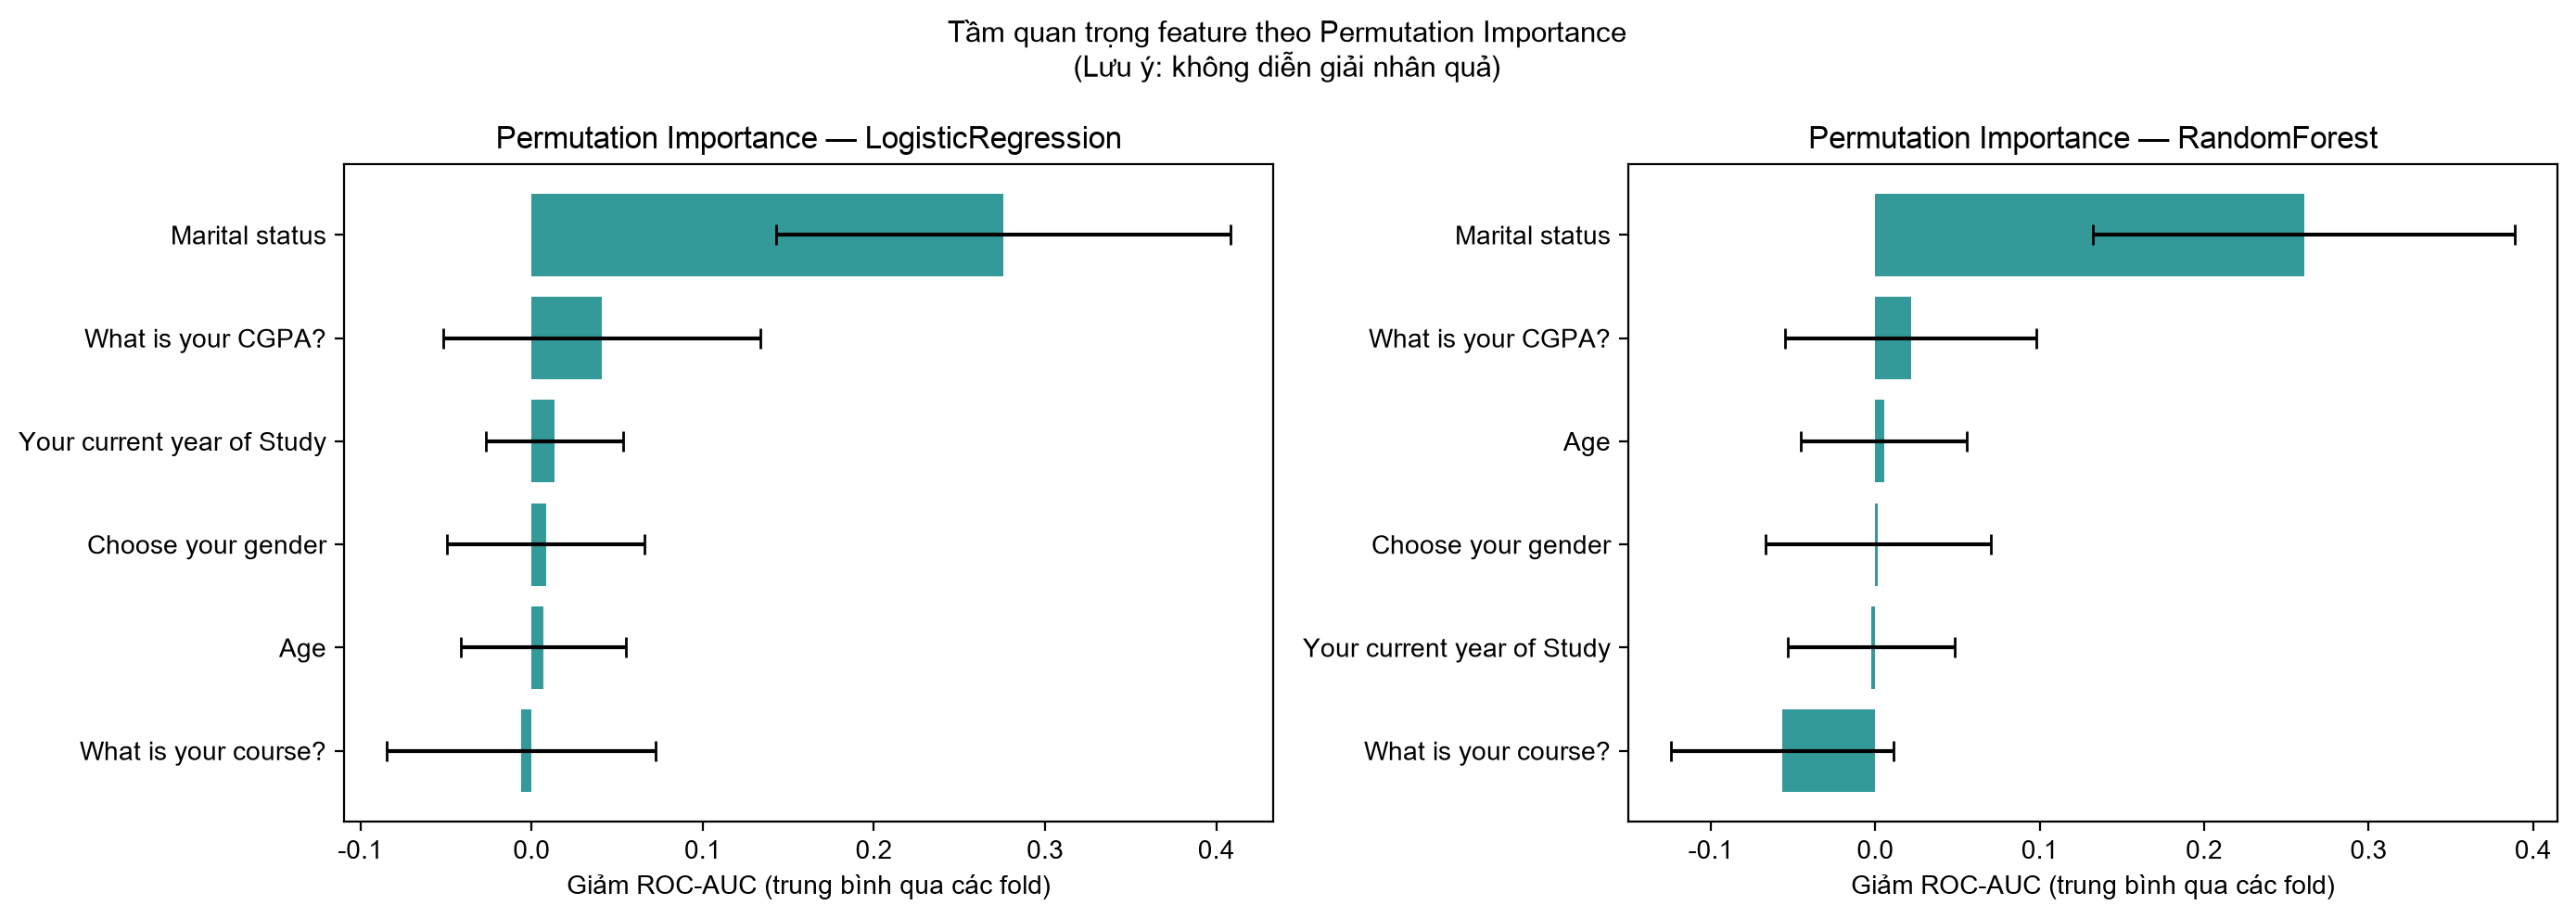

In [9]:
fig_path = plot_permutation_importance(perm_df)
print(f'Đã lưu: {fig_path}')
Image(str(fig_path))

In [10]:
# Hệ số LR trên toàn bộ dữ liệu (chỉ minh họa)
lr_pipe = get_models()['LogisticRegression']
lr_coef = lr_coefficients_table(lr_pipe, X.reset_index(drop=True), y.reset_index(drop=True))
lr_coef.to_csv(TABLES_DIR / 'error_lr_coefficients.csv', index=False, encoding='utf-8')
print('Hệ số LR (fit trên toàn bộ dữ liệu — CHỈ MINH HỌA, không dùng để đánh giá):')
print(df_to_markdown(lr_coef.head(20)))

Hệ số LR (fit trên toàn bộ dữ liệu — CHỈ MINH HỌA, không dùng để đánh giá):
| feature                                 |   coefficient |
|:----------------------------------------|--------------:|
| Marital status_No                       |        -1.769 |
| Marital status_Yes                      |         1.768 |
| What is your course?_psychology         |         1.051 |
| What is your course?_BENL               |         0.796 |
| What is your CGPA?_3.00 - 3.49          |         0.741 |
| What is your course?_Econs              |         0.730 |
| What is your course?_Malcom             |         0.629 |
| What is your course?_Biomedical science |        -0.615 |
| What is your course?_BIT                |         0.556 |
| What is your course?_KOE                |        -0.541 |
| What is your course?_Usuluddin          |         0.537 |
| Your current year of Study_year 4       |        -0.524 |
| What is your course?_Law                |         0.492 |
| What is your CGPA?_0 -

Đã lưu: D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\figures\09_lr_coefficients.png


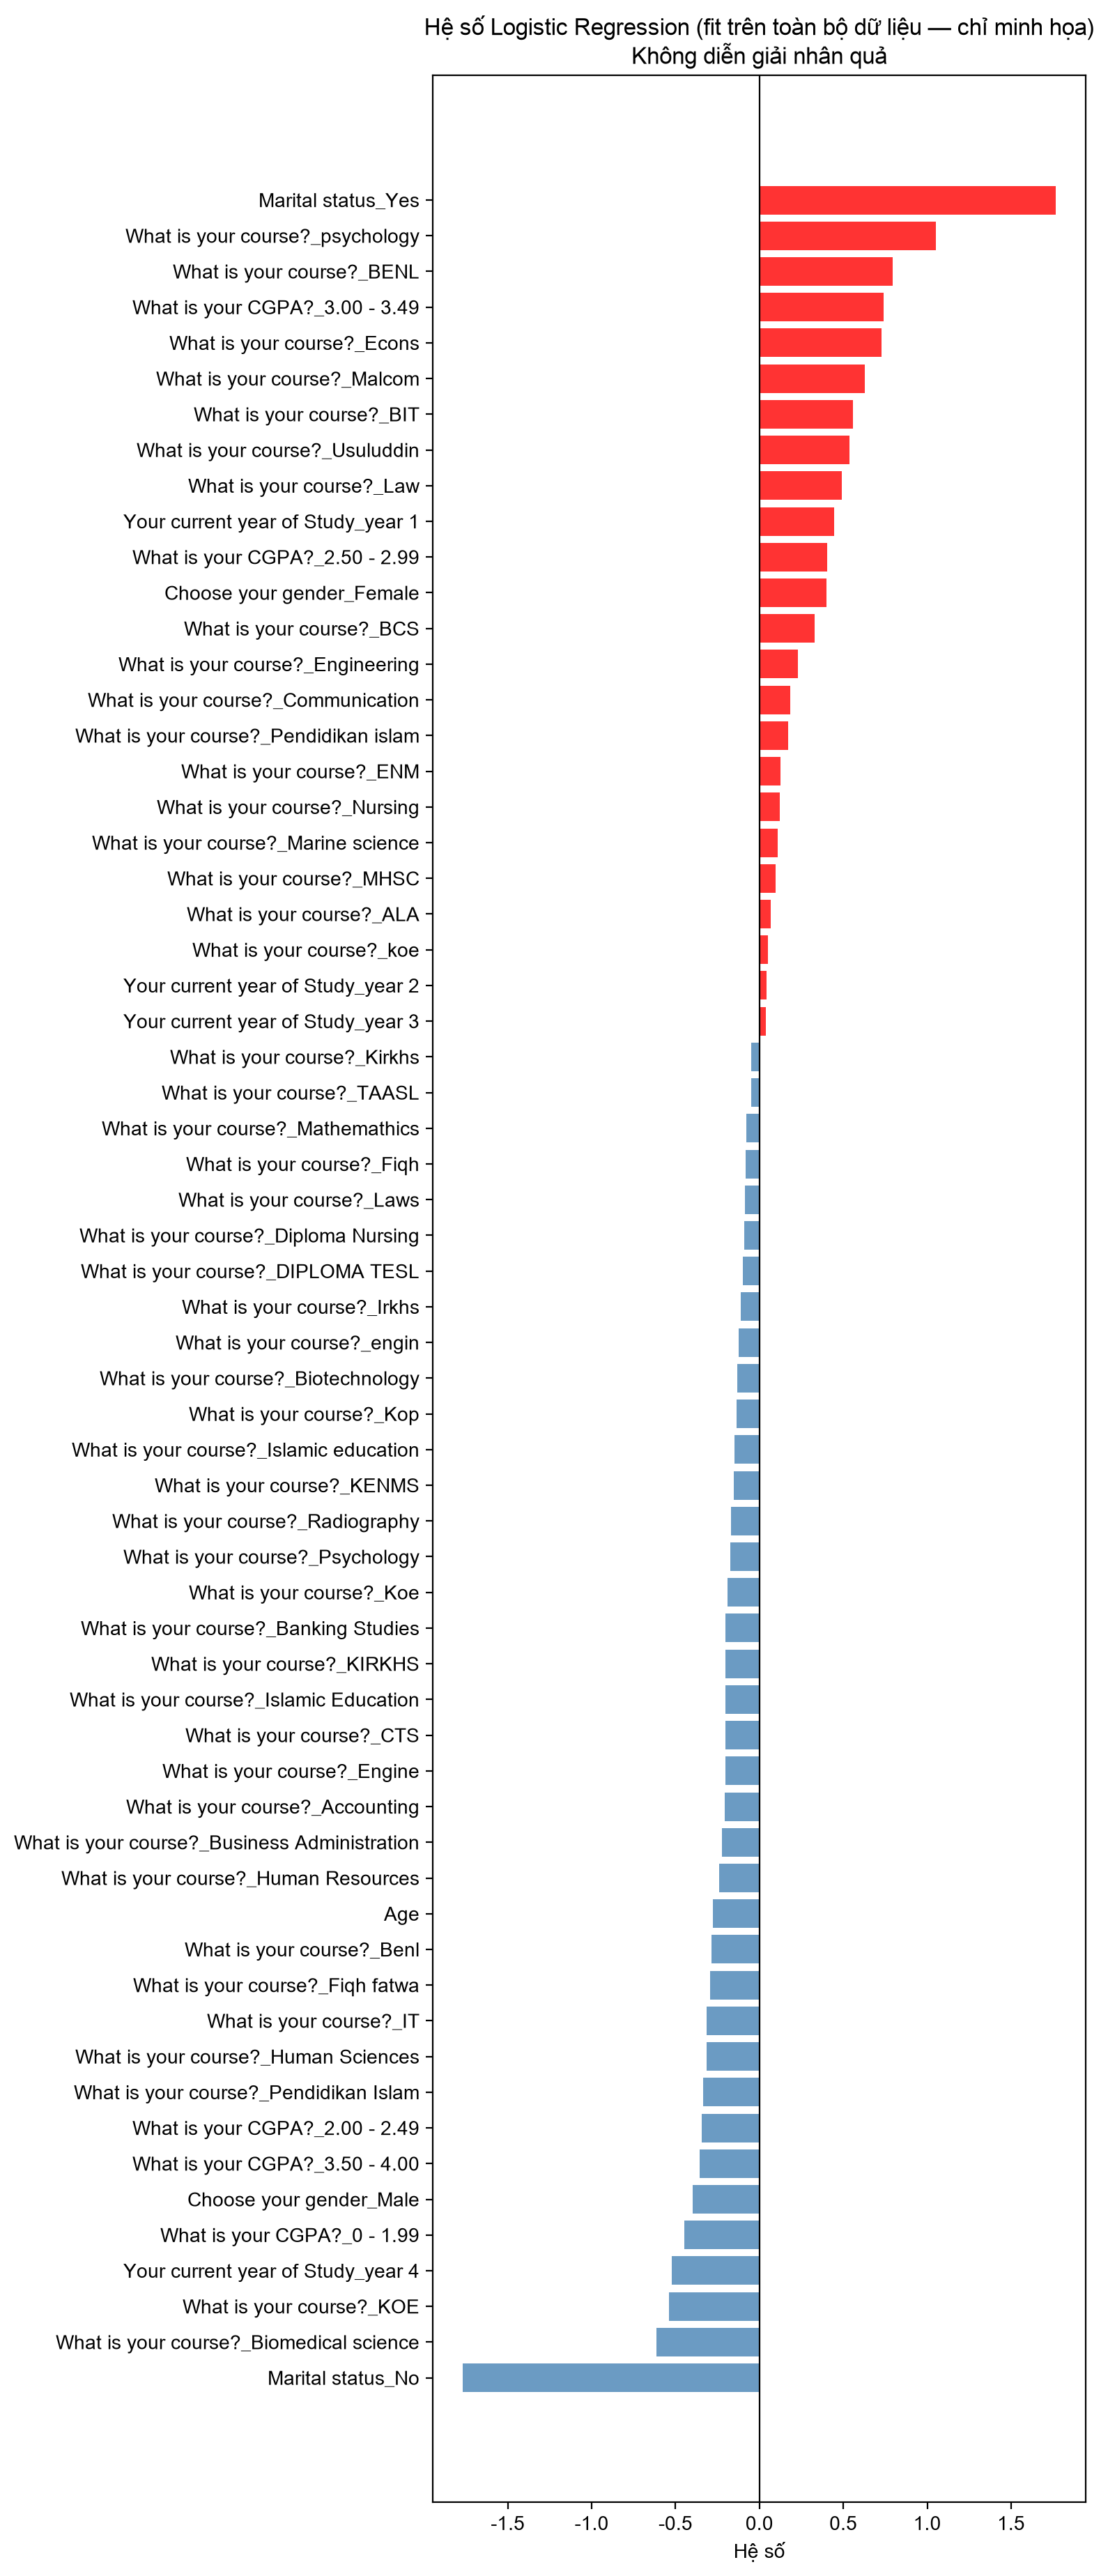

In [11]:
fig_path = plot_lr_coefficients(lr_coef)
print(f'Đã lưu: {fig_path}')
Image(str(fig_path))

In [12]:
# Cây quyết định trên toàn bộ dữ liệu (chỉ minh họa)
dt_pipe = clone(get_models()['DecisionTree'])
X_reset = X.reset_index(drop=True)
y_reset = y.reset_index(drop=True)
dt_pipe.fit(X_reset, y_reset)
feature_names = dt_pipe.named_steps['prep'].get_feature_names_out()
tree_text = export_text(dt_pipe.named_steps['clf'], feature_names=list(feature_names))
print('Cây quyết định (fit trên toàn bộ dữ liệu — CHỈ MINH HỌA):')
print(tree_text)

Cây quyết định (fit trên toàn bộ dữ liệu — CHỈ MINH HỌA):
|--- Marital status_No <= 0.50
|   |--- class: 1
|--- Marital status_No >  0.50
|   |--- What is your CGPA?_3.00 - 3.49 <= 0.50
|   |   |--- Your current year of Study_year 1 <= 0.50
|   |   |   |--- class: 0
|   |   |--- Your current year of Study_year 1 >  0.50
|   |   |   |--- class: 0
|   |--- What is your CGPA?_3.00 - 3.49 >  0.50
|   |   |--- Age <= 20.50
|   |   |   |--- class: 0
|   |   |--- Age >  20.50
|   |   |   |--- class: 0



## 7. Tổng kết Error Analysis

In [13]:
print('TÓM TẮT ERROR ANALYSIS (E0_main, LogisticRegression + best model):')
print()
print('- Marital status = Yes có liên hệ rất mạnh với nhãn Yes trong mẫu (16/16).')
print('  Mô hình sẽ dựa mạnh vào feature này. Chưa đủ căn cứ suy rộng.')
print('- FN (bỏ sót ca Yes) là vấn đề chính khi Recall thấp (~43-57%).')
print('- Các nhóm nhỏ (n < 10) có tỷ lệ sai không ổn định, không kết luận được.')
print('- Permutation importance cho thấy feature nào tương quan nhất với nhãn TRONG MẪU.')
print('  Không diễn giải nhân quả.')

TÓM TẮT ERROR ANALYSIS (E0_main, LogisticRegression + best model):

- Marital status = Yes có liên hệ rất mạnh với nhãn Yes trong mẫu (16/16).
  Mô hình sẽ dựa mạnh vào feature này. Chưa đủ căn cứ suy rộng.
- FN (bỏ sót ca Yes) là vấn đề chính khi Recall thấp (~43-57%).
- Các nhóm nhỏ (n < 10) có tỷ lệ sai không ổn định, không kết luận được.
- Permutation importance cho thấy feature nào tương quan nhất với nhãn TRONG MẪU.
  Không diễn giải nhân quả.
